# Atlanta vs Birmingham Climate Similarity Analysis

This notebook uses the two supplied master CSV files to determine, from the observed data, whether Atlanta and Birmingham form a defensible similar-climate pair for the cross-city LSTM experiment.

It performs data-quality checks, detects common weather variables, compares distributions and seasonal behavior, calculates standardized mean differences, Wasserstein distances, KS statistics, correlation-structure similarity, standardized multivariate climate distance, PCA visualization, and a transparent overall 0–100 similarity score.

**Energy is inspected separately and is not used to define climate similarity.**

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import wasserstein_distance, ks_2samp
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

ATLANTA_FILE = Path("../Atlanta/atlanta_master.csv")
BIRMINGHAM_FILE = Path("../Birmingham/birmingham_master.csv")

OUTPUT = Path.cwd()
TABLE_DIR, PLOT_DIR, REPORT_DIR = OUTPUT/"tables", OUTPUT/"plots", OUTPUT/"report"
for p in (TABLE_DIR, PLOT_DIR, REPORT_DIR):
    p.mkdir(parents=True, exist_ok=True)

print("Atlanta:", ATLANTA_FILE, ATLANTA_FILE.exists())
print("Birmingham:", BIRMINGHAM_FILE, BIRMINGHAM_FILE.exists())
print("Output:", OUTPUT)

if not ATLANTA_FILE.exists() or not BIRMINGHAM_FILE.exists():
    raise FileNotFoundError("Check the two CSV paths in this cell.")


Atlanta: D:\Downloads\BTP\model_training\lstm_training_2\Atlanta\atlanta_master.csv True
Birmingham: D:\Downloads\BTP\model_training\lstm_training_2\Birmingham\birmingham_master.csv True
Output: D:\Downloads\BTP\model_training\lstm_training_2\Atlanta\atlanta_birmingham_climate_similarity


## 1. Load and inspect the master CSVs

In [2]:
data = {
    "Atlanta": pd.read_csv(ATLANTA_FILE, low_memory=False),
    "Birmingham": pd.read_csv(BIRMINGHAM_FILE, low_memory=False),
}

for city, df in data.items():
    print("\n" + "="*80)
    print(city, "shape:", df.shape)
    print("Columns:", list(df.columns))
    display(df.head(5))



Atlanta shape: (70080, 26)
Columns: ['timestamp', 'hourly_load_mw', 'date', 'hour', 'extraterrestrial_horizontal_radiation_wh_m2', 'extraterrestrial_direct_normal_radiation_wh_m2', 'global_horizontal_radiation_wh_m2', 'direct_normal_radiation_wh_m2', 'diffuse_horizontal_radiation_wh_m2', 'total_sky_cover_tenths', 'opaque_sky_cover_tenths', 'temperature_c', 'dew_point_c', 'relative_humidity_percent', 'station_pressure_kpa', 'wind_direction_deg', 'wind_speed_ms', 'horizontal_visibility_km', 'ceiling_height_m', 'observation_indicator', 'present_weather', 'precipitable_water_mm', 'broadband_aerosol_optical_depth', 'snow_depth_cm', 'days_since_last_snowfall', 'hourly_precipitation_cm']


,timestamp,hourly_load_mw,date,hour,extraterrestrial_horizontal_radiation_wh_m2,extraterrestrial_direct_normal_radiation_wh_m2,global_horizontal_radiation_wh_m2,direct_normal_radiation_wh_m2,diffuse_horizontal_radiation_wh_m2,total_sky_cover_tenths,opaque_sky_cover_tenths,temperature_c,dew_point_c,relative_humidity_percent,station_pressure_kpa,wind_direction_deg,wind_speed_ms,horizontal_visibility_km,ceiling_height_m,observation_indicator,present_weather,precipitable_water_mm,broadband_aerosol_optical_depth,snow_depth_cm,days_since_last_snowfall,hourly_precipitation_cm
0,2016-01-01 00:00:00,"1,383.1916",2016-01-01,1,0.0000,0.0000,NaN,NaN,NaN,10.0000,10.0000,4.4000,3.3000,92.0000,98.7000,150.0000,2.3000,1.3000,60.0000,0,909999099,18.0000,0.1420,0.0000,88.0000,0.0300
1,2016-01-01 01:00:00,"1,407.4714",2016-01-01,2,0.0000,0.0000,NaN,NaN,NaN,10.0000,10.0000,4.4000,3.3000,93.0000,98.7000,160.0000,3.4000,1.3000,60.0000,0,909999099,19.0000,0.1420,0.0000,88.0000,0.0500
2,2016-01-01 02:00:00,"1,362.7851",2016-01-01,3,0.0000,0.0000,NaN,NaN,NaN,10.0000,10.0000,4.4000,3.3000,93.0000,98.8000,240.0000,2.8000,1.3000,60.0000,0,909999099,21.0000,0.1420,0.0000,88.0000,0.0800
3,2016-01-01 03:00:00,"1,315.8444",2016-01-01,4,0.0000,0.0000,NaN,NaN,NaN,10.0000,10.0000,4.4000,3.3000,93.0000,98.6000,120.0000,2.8000,1.3000,60.0000,0,909999099,22.0000,0.1420,0.0000,88.0000,0.1000
4,2016-01-01 04:00:00,"1,263.5274",2016-01-01,5,0.0000,0.0000,NaN,NaN,NaN,10.0000,10.0000,4.4000,3.9000,96.0000,98.6000,0.0000,0.0000,2.4000,60.0000,0,999999099,23.0000,0.1420,0.0000,88.0000,0.0000



Birmingham shape: (70080, 26)
Columns: ['timestamp', 'hourly_load_mw', 'date', 'hour', 'extraterrestrial_horizontal_radiation_wh_m2', 'extraterrestrial_direct_normal_radiation_wh_m2', 'global_horizontal_radiation_wh_m2', 'direct_normal_radiation_wh_m2', 'diffuse_horizontal_radiation_wh_m2', 'total_sky_cover_tenths', 'opaque_sky_cover_tenths', 'temperature_c', 'dew_point_c', 'relative_humidity_percent', 'station_pressure_kpa', 'wind_direction_deg', 'wind_speed_ms', 'horizontal_visibility_km', 'ceiling_height_m', 'observation_indicator', 'present_weather', 'precipitable_water_mm', 'broadband_aerosol_optical_depth', 'snow_depth_cm', 'days_since_last_snowfall', 'hourly_precipitation_cm']


,timestamp,hourly_load_mw,date,hour,extraterrestrial_horizontal_radiation_wh_m2,extraterrestrial_direct_normal_radiation_wh_m2,global_horizontal_radiation_wh_m2,direct_normal_radiation_wh_m2,diffuse_horizontal_radiation_wh_m2,total_sky_cover_tenths,opaque_sky_cover_tenths,temperature_c,dew_point_c,relative_humidity_percent,station_pressure_kpa,wind_direction_deg,wind_speed_ms,horizontal_visibility_km,ceiling_height_m,observation_indicator,present_weather,precipitable_water_mm,broadband_aerosol_optical_depth,snow_depth_cm,days_since_last_snowfall,hourly_precipitation_cm
0,2016-01-01 00:00:00,"1,221.1589",2016-01-01,1,0.0000,0.0000,NaN,NaN,NaN,10.0000,10.0000,7.2000,4.4000,83.0000,100.1000,360.0000,2.3000,9.7000,"2,440.0000",0,909999999,14.0000,0.1200,0.0000,20.0000,0.2500
1,2016-01-01 01:00:00,"1,240.5460",2016-01-01,2,0.0000,0.0000,NaN,NaN,NaN,10.0000,10.0000,6.7000,4.4000,86.0000,100.1000,40.0000,1.6000,11.3000,"3,050.0000",0,999999999,14.0000,0.1200,0.0000,20.0000,0.0000
2,2016-01-01 02:00:00,"1,202.0095",2016-01-01,3,0.0000,0.0000,NaN,NaN,NaN,10.0000,10.0000,7.2000,3.9000,80.0000,100.1000,110.0000,2.8000,11.3000,"1,160.0000",0,999999999,14.0000,0.1200,0.0000,20.0000,0.0000
3,2016-01-01 03:00:00,"1,161.3617",2016-01-01,4,0.0000,0.0000,NaN,NaN,NaN,10.0000,10.0000,7.2000,3.9000,80.0000,100.1000,0.0000,0.0000,11.3000,"3,050.0000",0,999999999,14.0000,0.1200,0.0000,20.0000,0.0000
4,2016-01-01 04:00:00,"1,116.2487",2016-01-01,5,0.0000,0.0000,NaN,NaN,NaN,10.0000,10.0000,6.7000,3.9000,83.0000,100.1000,0.0000,0.0000,11.3000,"3,050.0000",0,999999999,14.0000,0.1200,0.0000,20.0000,0.0000


## 2. Detect timestamp, energy and weather columns

In [3]:
TIME_ALIASES = ["timestamp","datetime","date_time","date","time","local_time","utc_time","start_time","end_time"]
ENERGY_ALIASES = ["energy","load","electricity","electricity_consumption","energy_consumption","power","mw","mwh","kwh","demand"]

WEATHER_ALIASES = {
    "temperature": ["temperature","temp","air_temperature","dry_bulb_temperature","drybulb","tmp"],
    "dew_point": ["dew_point","dewpoint","dew point","dew_point_temperature","dewp"],
    "relative_humidity": ["relative_humidity","humidity","rh","relative humidity"],
    "pressure": ["pressure","sea_level_pressure","station_pressure","atmospheric_pressure","slp","mslp"],
    "wind_speed": ["wind_speed","windspeed","wind speed","ws","wind"],
    "wind_direction": ["wind_direction","wind_dir","wind direction","wd"],
    "visibility": ["visibility","vis"],
    "precipitation": ["precipitation","precip","precipitation_amount","rain","rainfall"],
}

def nn(x):
    return "".join(ch for ch in str(x).lower().strip() if ch.isalnum())

def find_col(df, aliases):
    cols = {nn(c): c for c in df.columns}
    for a in aliases:
        if nn(a) in cols:
            return cols[nn(a)]
    for c in df.columns:
        nc = nn(c)
        for a in aliases:
            na = nn(a)
            if len(na) >= 4 and (na in nc or nc in na):
                return c
    return None

def find_time(df):
    candidates = []
    for c in df.columns:
        if any(nn(a) in nn(c) or nn(c) in nn(a) for a in TIME_ALIASES):
            p = pd.to_datetime(df[c], errors="coerce")
            candidates.append((p.notna().mean(), c))
    candidates.sort(reverse=True)
    return candidates[0][1] if candidates and candidates[0][0] >= .5 else None

maps = {}
for city, df in data.items():
    maps[city] = {
        "time": find_time(df),
        "energy": find_col(df, ENERGY_ALIASES),
        "weather": {f: find_col(df, a) for f,a in WEATHER_ALIASES.items()}
    }
    print("\n", city)
    print("timestamp:", maps[city]["time"])
    print("energy:", maps[city]["energy"])
    for f,c in maps[city]["weather"].items():
        print(f"{f:20s} -> {c}")

common_features = [f for f in WEATHER_ALIASES
                   if maps["Atlanta"]["weather"].get(f)
                   and maps["Birmingham"]["weather"].get(f)]

print("\nCOMMON WEATHER VARIABLES:", common_features)
if len(common_features) < 3:
    raise ValueError("Fewer than 3 common weather variables detected. Add aliases in WEATHER_ALIASES.")



 Atlanta
timestamp: timestamp
energy: hourly_load_mw
temperature          -> temperature_c
dew_point            -> dew_point_c
relative_humidity    -> relative_humidity_percent
pressure             -> station_pressure_kpa
wind_speed           -> wind_direction_deg
wind_direction       -> wind_direction_deg
visibility           -> horizontal_visibility_km
precipitation        -> precipitable_water_mm

 Birmingham
timestamp: timestamp
energy: hourly_load_mw
temperature          -> temperature_c
dew_point            -> dew_point_c
relative_humidity    -> relative_humidity_percent
pressure             -> station_pressure_kpa
wind_speed           -> wind_direction_deg
wind_direction       -> wind_direction_deg
visibility           -> horizontal_visibility_km
precipitation        -> precipitable_water_mm

COMMON WEATHER VARIABLES: ['temperature', 'dew_point', 'relative_humidity', 'pressure', 'wind_speed', 'wind_direction', 'visibility', 'precipitation']


## 3. Data-quality audit and normalized weather tables

In [4]:
audit = []
weather = {}

for city, df in data.items():
    tcol = maps[city]["time"]
    ts = pd.to_datetime(df[tcol], errors="coerce")
    audit.append({
        "city": city, "rows": len(df), "columns": df.shape[1],
        "timestamp_column": tcol,
        "valid_timestamp_pct": ts.notna().mean()*100,
        "start": ts.min(), "end": ts.max(),
        "duplicate_rows": int(df.duplicated().sum()),
        "missing_cells": int(df.isna().sum().sum()),
        "missing_cell_pct": df.isna().mean().mean()*100,
        "energy_column": maps[city]["energy"]
    })

    w = pd.DataFrame({"timestamp": ts})
    for f in common_features:
        w[f] = pd.to_numeric(df[maps[city]["weather"][f]], errors="coerce")
    w = w.dropna(subset=["timestamp"]).sort_values("timestamp")
    w = w.drop_duplicates("timestamp", keep="first").set_index("timestamp")
    w = w.loc[(w.index >= "2016-01-01") & (w.index < "2024-01-01")]
    weather[city] = w

audit = pd.DataFrame(audit)
display(audit)
audit.to_csv(TABLE_DIR/"data_quality_audit.csv", index=False)

start = max(weather[c].index.min() for c in weather)
end = min(weather[c].index.max() for c in weather)
aligned = {c: weather[c].loc[start:end].copy() for c in weather}

coverage = pd.DataFrame({
    c: {"rows":len(d), "unique_timestamps":d.index.nunique(),
        "complete_weather_row_pct":d[common_features].notna().all(axis=1).mean()*100,
        "start":d.index.min(), "end":d.index.max()}
    for c,d in aligned.items()
}).T
display(coverage)
coverage.to_csv(TABLE_DIR/"weather_coverage.csv")

q = []
for city,d in aligned.items():
    for f in common_features:
        q.append({"city":city,"feature":f,"missing":int(d[f].isna().sum()),
                  "missing_pct":d[f].isna().mean()*100})
quality = pd.DataFrame(q)
display(quality)
quality.to_csv(TABLE_DIR/"weather_quality.csv", index=False)

print("COMMON PERIOD:", start, "to", end)


,city,rows,columns,timestamp_column,valid_timestamp_pct,start,end,duplicate_rows,missing_cells,missing_cell_pct,energy_column
0,Atlanta,70080,26,timestamp,100.0000,2016-01-01,2023-12-31 23:00:00,0,210240,11.5385,hourly_load_mw
1,Birmingham,70080,26,timestamp,100.0000,2016-01-01,2023-12-31 23:00:00,0,210240,11.5385,hourly_load_mw


,rows,unique_timestamps,complete_weather_row_pct,start,end
Atlanta,70080,70080,100.0000,2016-01-01 00:00:00,2023-12-31 23:00:00
Birmingham,70080,70080,100.0000,2016-01-01 00:00:00,2023-12-31 23:00:00


,city,feature,missing,missing_pct
0,Atlanta,temperature,0,0.0000
1,Atlanta,dew_point,0,0.0000
2,Atlanta,relative_humidity,0,0.0000
3,Atlanta,pressure,0,0.0000
4,Atlanta,wind_speed,0,0.0000
5,Atlanta,wind_direction,0,0.0000
6,Atlanta,visibility,0,0.0000
7,Atlanta,precipitation,0,0.0000
8,Birmingham,temperature,0,0.0000
9,Birmingham,dew_point,0,0.0000


COMMON PERIOD: 2016-01-01 00:00:00 to 2023-12-31 23:00:00


## 4. Descriptive statistics

In [5]:
rows=[]
for city,d in aligned.items():
    x=d[common_features].describe(percentiles=[.25,.50,.75]).T
    x["city"]=city; x["feature"]=x.index
    rows.append(x.reset_index(drop=True))
desc=pd.concat(rows, ignore_index=True)
desc=desc[["city","feature","count","mean","std","min","25%","50%","75%","max"]]
display(desc)
desc.to_csv(TABLE_DIR/"descriptive_statistics.csv", index=False)


,city,feature,count,mean,std,min,25%,50%,75%,max
0,Atlanta,temperature,"70,080.0000",16.7739,9.0464,-22.2000,10.0000,17.8000,23.3000,38.9000
1,Atlanta,dew_point,"70,080.0000",9.5283,9.5534,-33.3000,2.2000,11.1000,18.3000,25.0000
2,Atlanta,relative_humidity,"70,080.0000",65.9550,20.5050,12.0000,50.0000,67.0000,84.0000,100.0000
3,Atlanta,pressure,"70,080.0000",98.1292,0.5145,94.6000,97.8000,98.1000,98.4000,100.3000
4,Atlanta,wind_speed,"70,080.0000",200.3385,104.5206,0.0000,100.0000,220.0000,300.0000,360.0000
5,Atlanta,wind_direction,"70,080.0000",200.3385,104.5206,0.0000,100.0000,220.0000,300.0000,360.0000
6,Atlanta,visibility,"70,080.0000",18.8014,10.1335,0.0000,11.3000,16.1000,24.1000,64.4000
7,Atlanta,precipitation,"70,080.0000",22.9466,12.1912,1.0000,12.0000,22.0000,33.0000,71.0000
8,Birmingham,temperature,"70,080.0000",16.7063,9.3995,-21.1000,10.0000,17.8000,23.3000,38.9000
9,Birmingham,dew_point,"70,080.0000",10.3371,9.4092,-29.4000,3.3000,12.2000,18.9000,28.3000


## 5. Distribution similarity

For every common weather variable:
- **SMD** measures standardized difference in means.
- **Wasserstein distance** compares the empirical distributions.
- **KS statistic** compares empirical cumulative distributions.

All are converted to 0–100 similarity measures, where higher is more similar.

In [6]:
rows=[]
for f in common_features:
    a=aligned["Atlanta"][f].dropna().values
    b=aligned["Birmingham"][f].dropna().values
    ma,mb=np.mean(a),np.mean(b)
    sa,sb=np.std(a,ddof=1),np.std(b,ddof=1)
    ps=np.sqrt((sa**2+sb**2)/2)
    smd=abs(ma-mb)/ps if ps>0 else np.nan
    wd=wasserstein_distance(a,b)
    nwd=wd/ps if ps>0 else np.nan
    ks=ks_2samp(a,b)
    smd_s=100*np.exp(-smd)
    wd_s=100*np.exp(-nwd)
    ks_s=100*(1-ks.statistic)
    score=(smd_s+wd_s+ks_s)/3
    rows.append({
        "feature":f,"Atlanta_mean":ma,"Birmingham_mean":mb,
        "Atlanta_std":sa,"Birmingham_std":sb,
        "SMD":smd,"Wasserstein_distance":wd,"normalized_Wasserstein":nwd,
        "KS_statistic":ks.statistic,"KS_p_value":ks.pvalue,
        "SMD_similarity":smd_s,"Wasserstein_similarity":wd_s,
        "KS_similarity":ks_s,"variable_similarity_score":score
    })
varsim=pd.DataFrame(rows).sort_values("variable_similarity_score",ascending=False)
display(varsim)
varsim.to_csv(TABLE_DIR/"variable_similarity.csv",index=False)


,feature,Atlanta_mean,Birmingham_mean,Atlanta_std,Birmingham_std,SMD,Wasserstein_distance,normalized_Wasserstein,KS_statistic,KS_p_value,SMD_similarity,Wasserstein_similarity,KS_similarity,variable_similarity_score
0,temperature,16.7739,16.7063,9.0464,9.3995,0.0073,0.2589,0.0281,0.0131,0.0000,99.2699,97.2328,98.6943,98.3990
7,precipitation,22.9466,22.7978,12.1912,10.7935,0.0129,1.1009,0.0956,0.0549,0.0000,98.7153,90.8814,94.5063,94.7010
1,dew_point,9.5283,10.3371,9.5534,9.4092,0.0853,0.8112,0.0856,0.0408,0.0000,91.8234,91.8002,95.9232,93.1823
2,relative_humidity,65.9550,69.8845,20.5050,20.7641,0.1904,3.9296,0.1904,0.1002,0.0000,82.6602,82.6600,89.9829,85.1010
5,wind_direction,200.3385,145.2895,104.5206,119.2575,0.4909,57.3909,0.5118,0.2590,0.0000,61.2055,59.9405,74.1039,65.0833
4,wind_speed,200.3385,145.2895,104.5206,119.2575,0.4909,57.3909,0.5118,0.2590,0.0000,61.2055,59.9405,74.1039,65.0833
6,visibility,18.8014,11.6723,10.1335,4.4052,0.9124,7.2567,0.9288,0.4062,0.0000,40.1544,39.5036,59.3807,46.3462
3,pressure,98.1292,99.5945,0.5145,0.5326,2.7981,1.4652,2.7981,0.8600,0.0000,6.0923,6.0923,14.0011,8.7286


## 6. Distribution and monthly climatology plots

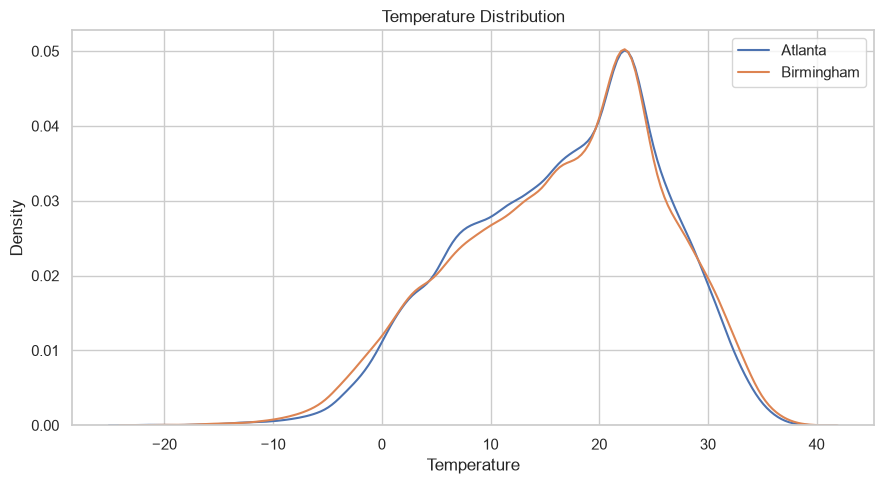

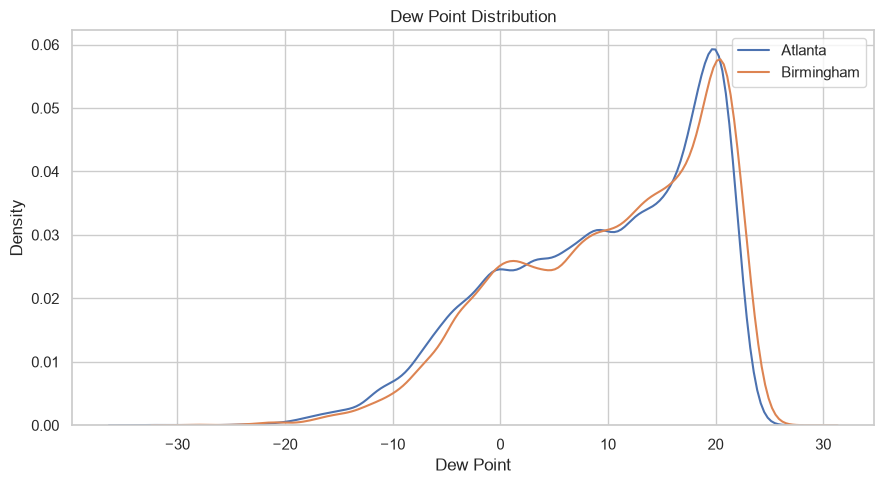

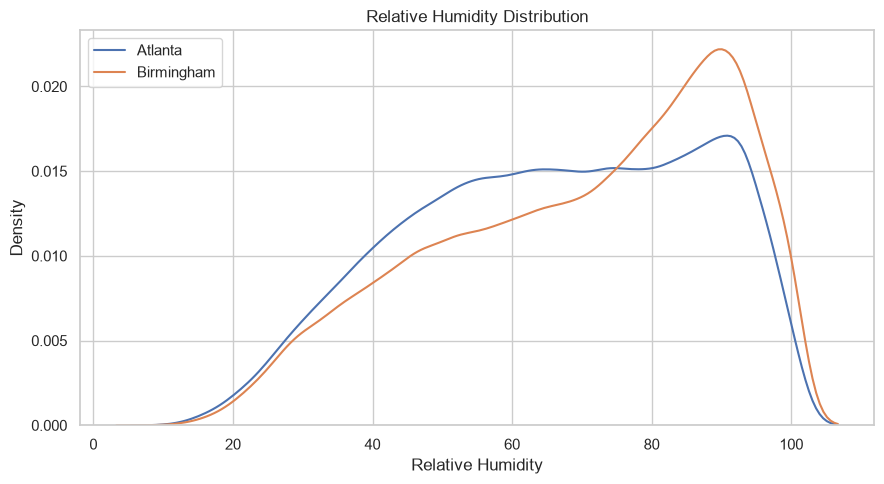

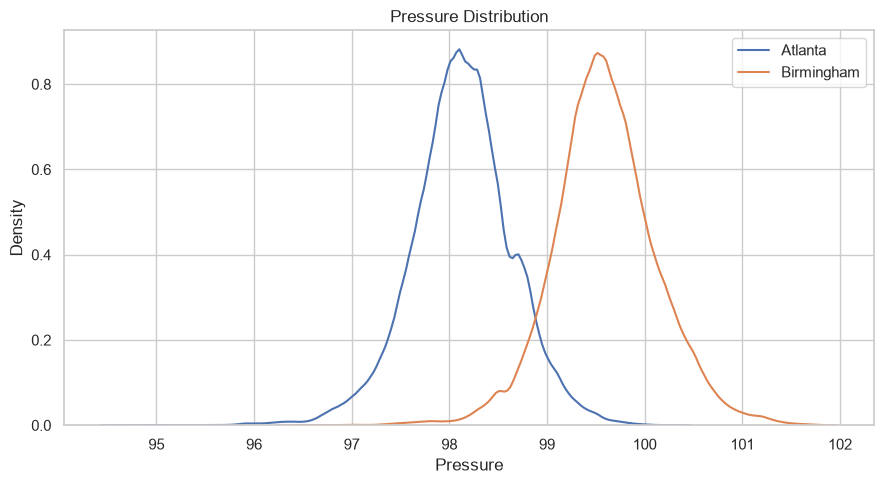

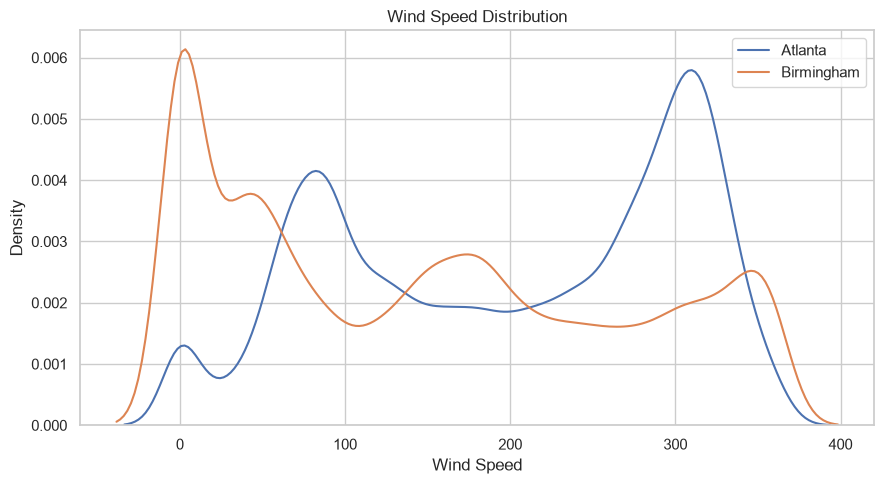

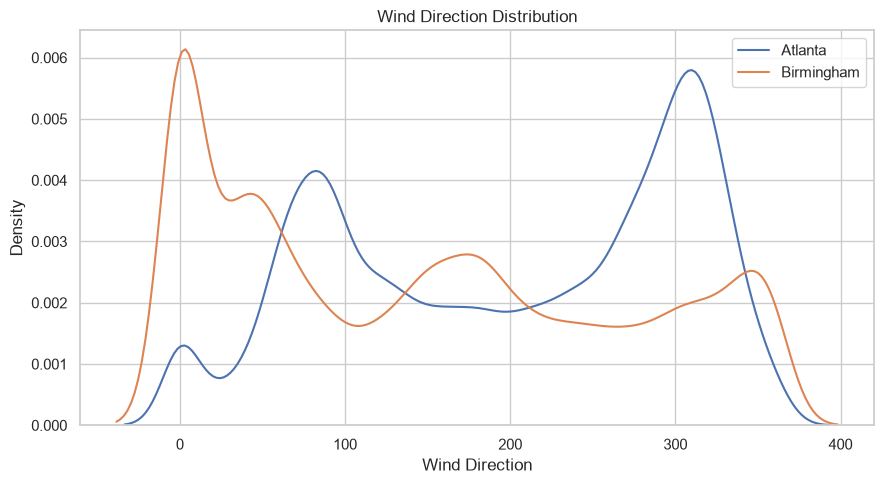

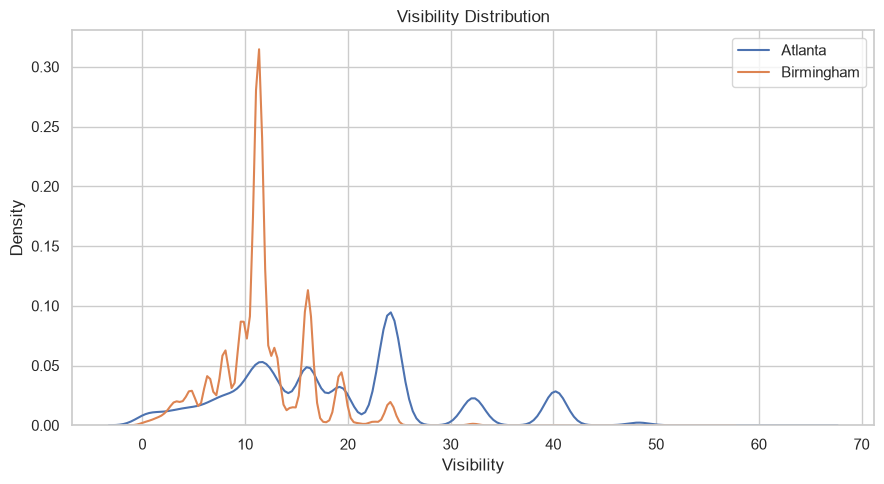

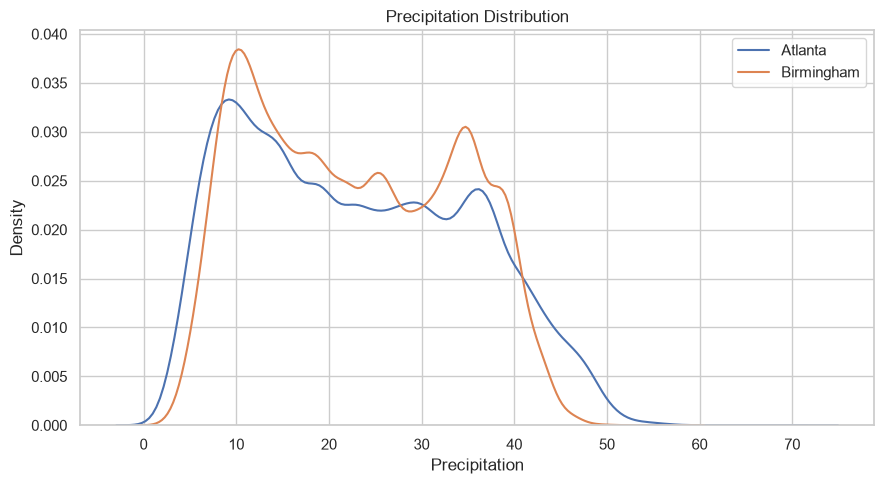

,temperature,dew_point,relative_humidity,pressure,wind_speed,wind_direction,visibility,precipitation,city,month
0,5.6570,-1.4392,64.4790,98.2868,213.2577,213.2577,19.3526,11.3906,Atlanta,1
1,8.3134,0.8970,64.0722,98.1394,208.8077,208.8077,19.8820,12.9874,Atlanta,2
2,12.4222,4.0338,61.4365,98.0341,204.1751,204.1751,20.7200,14.6986,Atlanta,3
3,16.2718,6.5744,57.2071,97.8298,223.9896,223.9896,23.3729,16.9297,Atlanta,4
4,20.8829,13.0473,64.3915,97.9595,208.6979,208.6979,20.2351,24.8953,Atlanta,5
5,25.1310,17.3853,65.3306,98.0048,200.7431,200.7431,16.4898,32.5512,Atlanta,6
6,26.2257,19.6130,69.6937,98.1342,209.0843,209.0843,14.2032,37.4424,Atlanta,7
7,25.9485,19.8435,71.3196,98.0730,186.7692,186.7692,14.2071,38.4598,Atlanta,8
8,22.4670,16.3856,71.0380,98.1943,165.4948,165.4948,16.6058,30.8378,Atlanta,9
9,17.3301,10.3286,67.0272,98.2987,178.4358,178.4358,19.8874,22.6037,Atlanta,10


,temperature,dew_point,relative_humidity,pressure,wind_speed,wind_direction,visibility,precipitation,city,season
0,17.5444,11.0050,68.7691,98.2364,179.4940,179.4940,19.0790,23.8095,Atlanta,Autumn
1,16.5284,7.8994,61.0530,97.9423,212.1603,212.1603,21.4217,18.8620,Atlanta,Spring
2,25.7753,18.9642,68.8188,98.0714,198.8451,198.8451,14.9501,36.1903,Atlanta,Summer
3,7.0441,0.0546,65.1930,98.2709,210.8568,210.8568,19.7789,12.7116,Atlanta,Winter
4,17.4506,11.6106,72.2169,99.6800,130.0363,130.0363,12.1075,23.3872,Birmingham,Autumn
5,16.5132,8.9278,65.4096,99.4042,156.2741,156.2741,12.3960,19.8820,Birmingham,Spring
6,25.6626,19.6039,72.1791,99.4748,133.7319,133.7319,10.5446,34.8709,Birmingham,Summer
7,6.9956,1.0173,69.7550,99.8248,161.2980,161.2980,11.6453,12.8409,Birmingham,Winter


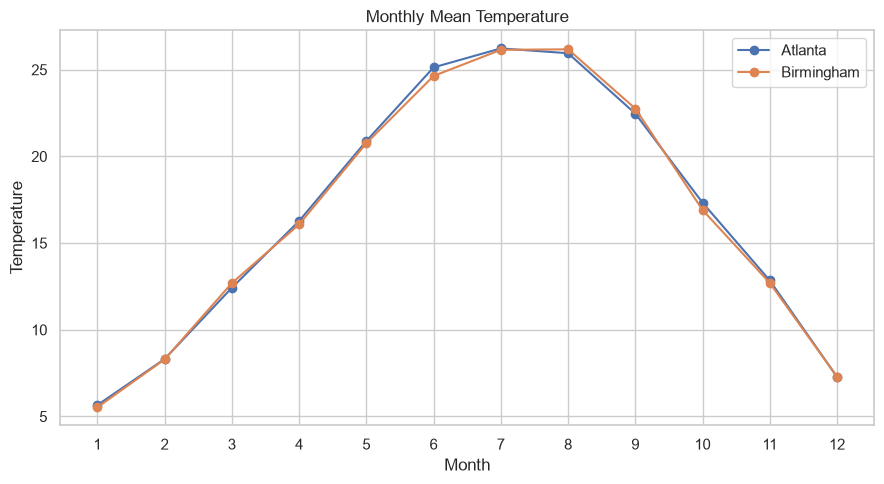

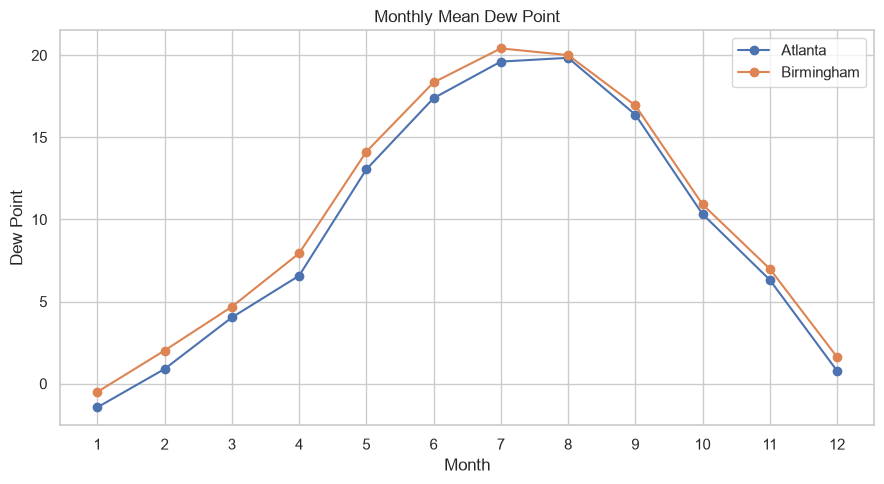

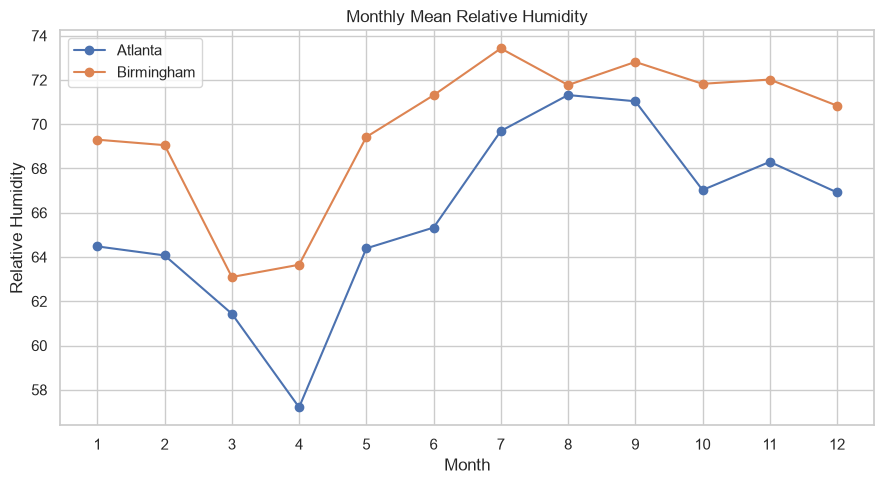

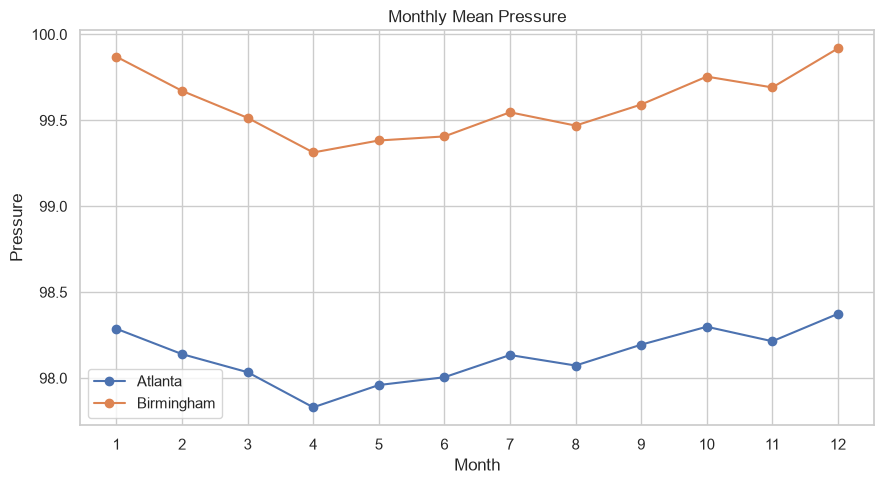

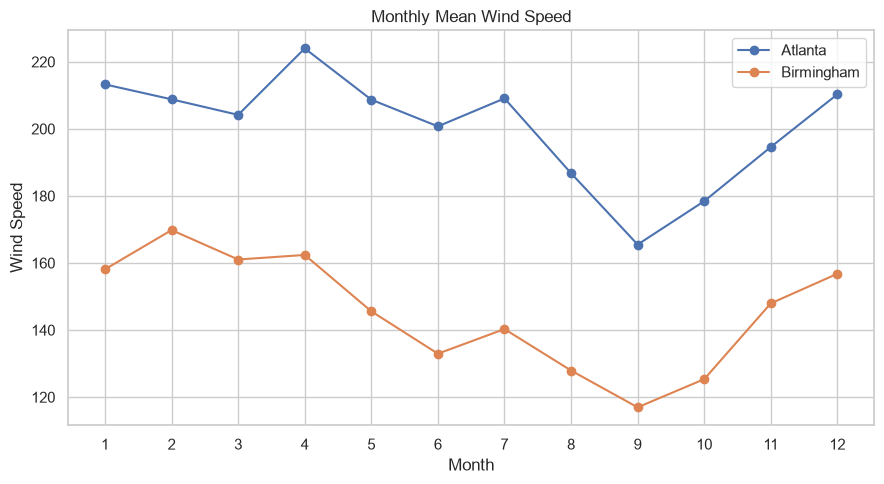

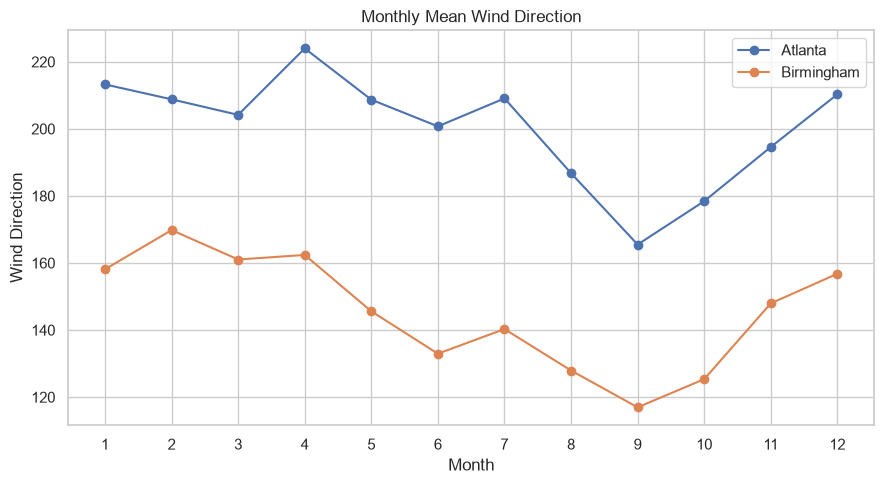

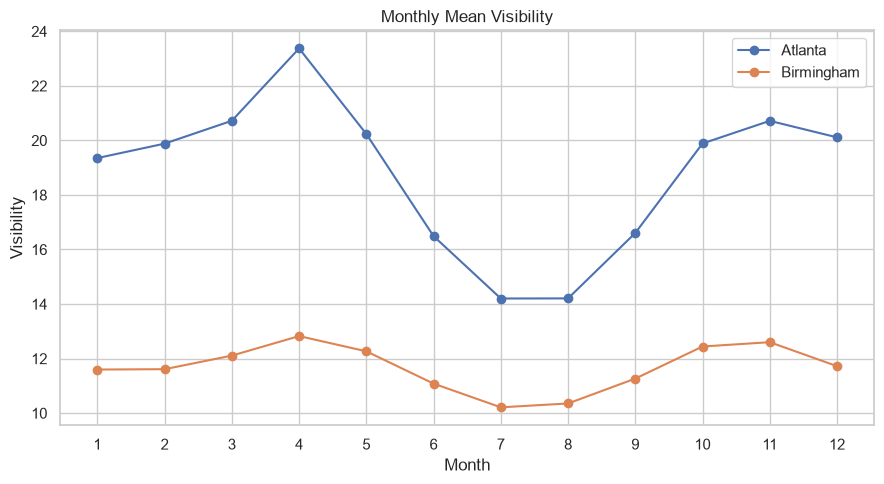

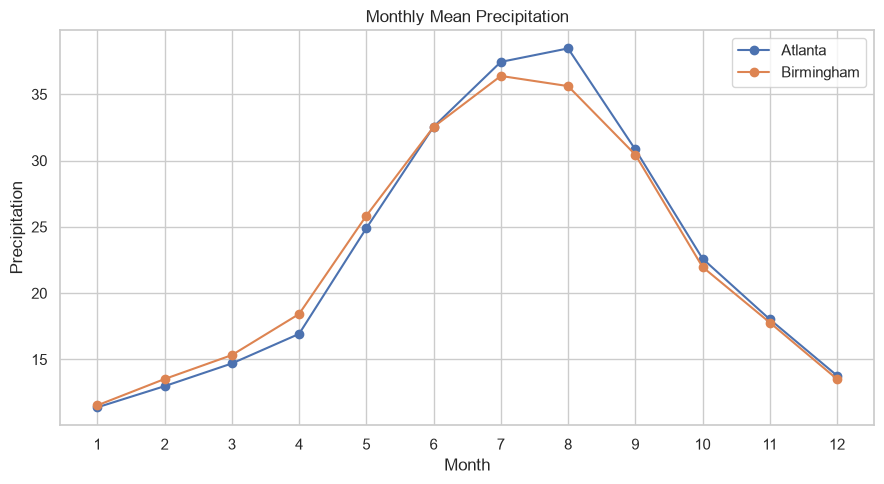

In [7]:
for f in common_features:
    fig,ax=plt.subplots(figsize=(9,5))
    for city in ["Atlanta","Birmingham"]:
        sns.kdeplot(aligned[city][f].dropna(),ax=ax,label=city,fill=False)
    ax.set_title(f"{f.replace('_',' ').title()} Distribution")
    ax.set_xlabel(f.replace("_"," ").title()); ax.set_ylabel("Density"); ax.legend()
    fig.tight_layout(); fig.savefig(PLOT_DIR/f"{f}_distribution.png",dpi=180,bbox_inches="tight")
    plt.show(); plt.close(fig)

monthly=[]
season_map={12:"Winter",1:"Winter",2:"Winter",3:"Spring",4:"Spring",5:"Spring",
            6:"Summer",7:"Summer",8:"Summer",9:"Autumn",10:"Autumn",11:"Autumn"}
seasonal=[]
for city,d in aligned.items():
    x=d.copy(); x["month"]=x.index.month; x["season"]=x.index.month.map(season_map)
    m=x.groupby("month")[common_features].mean(); m["city"]=city; m["month"]=m.index
    monthly.append(m.reset_index(drop=True))
    s=x.groupby("season")[common_features].mean(); s["city"]=city; s["season"]=s.index
    seasonal.append(s.reset_index(drop=True))
monthly=pd.concat(monthly,ignore_index=True); seasonal=pd.concat(seasonal,ignore_index=True)
display(monthly); display(seasonal)
monthly.to_csv(TABLE_DIR/"monthly_weather_means.csv",index=False)
seasonal.to_csv(TABLE_DIR/"seasonal_weather_means.csv",index=False)

for f in common_features:
    fig,ax=plt.subplots(figsize=(9,5))
    for city in ["Atlanta","Birmingham"]:
        x=monthly[monthly.city==city]
        ax.plot(x.month,x[f],marker="o",label=city)
    ax.set_xticks(range(1,13)); ax.set_title(f"Monthly Mean {f.replace('_',' ').title()}")
    ax.set_xlabel("Month"); ax.set_ylabel(f.replace("_"," ").title()); ax.legend()
    fig.tight_layout(); fig.savefig(PLOT_DIR/f"{f}_monthly.png",dpi=180,bbox_inches="tight")
    plt.show(); plt.close(fig)


## 7. Correlation structure similarity

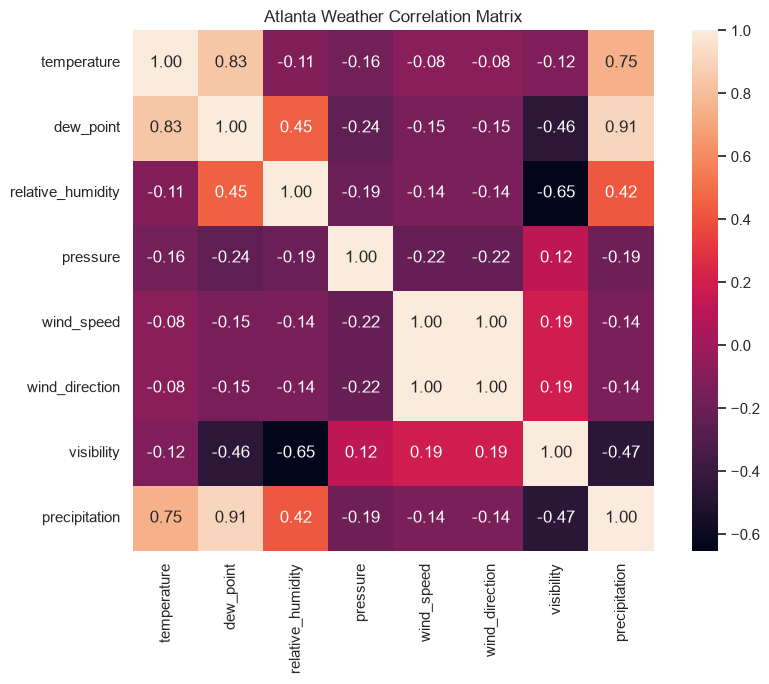

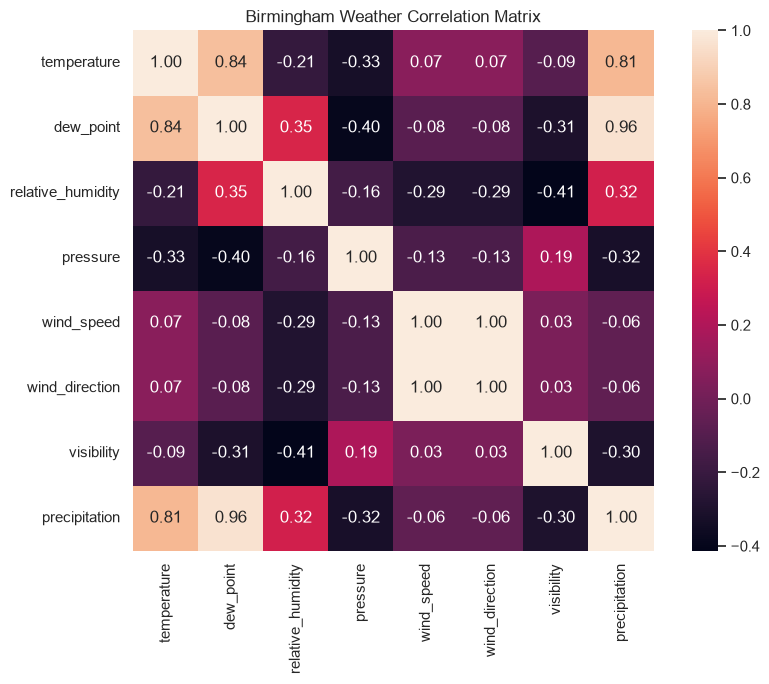

Mean absolute correlation difference: 0.1039
Correlation similarity: 89.61/100


In [8]:
corr={}
for city,d in aligned.items():
    corr[city]=d[common_features].corr()
    corr[city].to_csv(TABLE_DIR/f"{city.lower()}_correlation.csv")
    fig,ax=plt.subplots(figsize=(9,7))
    sns.heatmap(corr[city],annot=True,fmt=".2f",square=True,ax=ax)
    ax.set_title(f"{city} Weather Correlation Matrix")
    fig.tight_layout(); fig.savefig(PLOT_DIR/f"{city.lower()}_correlation_heatmap.png",dpi=180,bbox_inches="tight")
    plt.show(); plt.close(fig)

diff=corr["Atlanta"]-corr["Birmingham"]
upper=np.triu_indices_from(diff,k=1)
mean_corr_diff=float(np.mean(np.abs(diff.values[upper])))
corr_score=float(np.clip(1-mean_corr_diff,0,1)*100)
print(f"Mean absolute correlation difference: {mean_corr_diff:.4f}")
print(f"Correlation similarity: {corr_score:.2f}/100")
diff.to_csv(TABLE_DIR/"correlation_difference.csv")


## 8. Standardized multivariate climate distance and PCA

,Atlanta,Birmingham
temperature,0.0037,-0.0037
dew_point,-0.0426,0.0426
relative_humidity,-0.0948,0.0948
pressure,-0.8136,0.8136
wind_speed,0.2384,-0.2384
wind_direction,0.2384,-0.2384
visibility,0.4151,-0.4151
precipitation,0.0065,-0.0065


Standardized multivariate climate distance: 1.9582
Multivariate similarity: 14.11/100


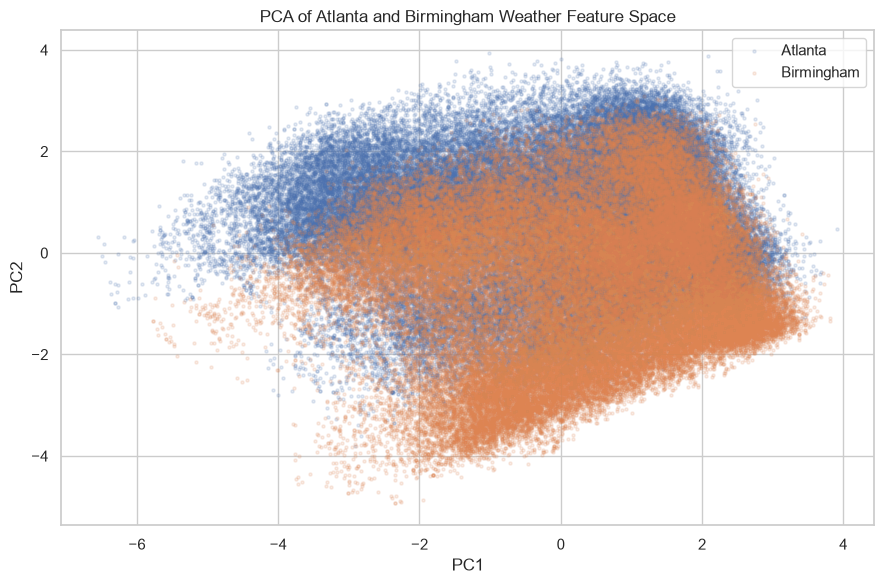

In [9]:
pooled=pd.concat([
    aligned["Atlanta"][common_features].assign(city="Atlanta"),
    aligned["Birmingham"][common_features].assign(city="Birmingham")
],ignore_index=True)

valid=pooled.dropna(subset=common_features)
scaler=StandardScaler().fit(valid[common_features])

vectors={}
for city in ["Atlanta","Birmingham"]:
    vectors[city]=np.mean(scaler.transform(aligned[city][common_features].dropna()),axis=0)

vectors=pd.DataFrame(vectors,index=common_features)
display(vectors)

multi_distance=float(np.linalg.norm(vectors["Atlanta"]-vectors["Birmingham"]))
multi_score=float(100*np.exp(-multi_distance))

print(f"Standardized multivariate climate distance: {multi_distance:.4f}")
print(f"Multivariate similarity: {multi_score:.2f}/100")
vectors.to_csv(TABLE_DIR/"standardized_climate_vectors.csv")

pca_input=pooled.dropna(subset=common_features)
coords=PCA(n_components=2,random_state=42).fit_transform(scaler.transform(pca_input[common_features]))
pca_df=pd.DataFrame(coords,columns=["PC1","PC2"]); pca_df["city"]=pca_input.city.values
fig,ax=plt.subplots(figsize=(9,6))
for city in ["Atlanta","Birmingham"]:
    x=pca_df[pca_df.city==city]
    ax.scatter(x.PC1,x.PC2,s=5,alpha=.15,label=city)
ax.set_title("PCA of Atlanta and Birmingham Weather Feature Space")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend()
fig.tight_layout(); fig.savefig(PLOT_DIR/"pca_climate_space.png",dpi=180,bbox_inches="tight")
plt.show(); plt.close(fig)
pca_df.to_csv(TABLE_DIR/"pca_coordinates.csv",index=False)


## 9. Final climate similarity score

The project score combines:
- 60% variable-level distribution similarity
- 20% weather correlation-structure similarity
- 20% standardized multivariate similarity

Interpretation:
- **80–100:** Highly similar
- **65–79.99:** Similar
- **50–64.99:** Moderately similar
- **Below 50:** Dissimilar

These thresholds are project-defined decision rules, not universal climatological standards.

In [10]:
distribution_score=float(varsim.variable_similarity_score.mean())
overall_score=.60*distribution_score+.20*corr_score+.20*multi_score

if overall_score>=80: classification="Highly similar"
elif overall_score>=65: classification="Similar"
elif overall_score>=50: classification="Moderately similar"
else: classification="Dissimilar"

scores=pd.DataFrame({
    "component":["Distribution similarity","Correlation structure similarity",
                 "Multivariate climate similarity","Overall climate similarity"],
    "score_0_to_100":[distribution_score,corr_score,multi_score,overall_score],
    "weight":[.60,.20,.20,1.00]
})
display(scores)
print(f"FINAL CLIMATE SIMILARITY SCORE: {overall_score:.2f}/100")
print(f"CLASSIFICATION: {classification}")
scores.to_csv(TABLE_DIR/"final_similarity_scores.csv",index=False)


,component,score_0_to_100,weight
0,Distribution similarity,69.5781,0.6000
1,Correlation structure similarity,89.6078,0.2000
2,Multivariate climate similarity,14.1108,0.2000
3,Overall climate similarity,62.4906,1.0000


FINAL CLIMATE SIMILARITY SCORE: 62.49/100
CLASSIFICATION: Moderately similar


## 10. Energy context audit

In [11]:
energy=[]
for city,df in data.items():
    ecol=maps[city]["energy"]; tcol=maps[city]["time"]
    e=pd.to_numeric(df[ecol],errors="coerce") if ecol else pd.Series(dtype=float)
    ts=pd.to_datetime(df[tcol],errors="coerce")
    energy.append({
        "city":city,"energy_column":ecol,"rows":len(df),
        "energy_missing_pct":e.isna().mean()*100 if ecol else np.nan,
        "energy_mean":e.mean() if ecol else np.nan,
        "energy_std":e.std() if ecol else np.nan,
        "start":ts.min(),"end":ts.max()
    })
energy=pd.DataFrame(energy)
display(energy)
energy.to_csv(TABLE_DIR/"energy_context_audit.csv",index=False)


,city,energy_column,rows,energy_missing_pct,energy_mean,energy_std,start,end
0,Atlanta,hourly_load_mw,70080,0.0000,"1,571.0310",326.7680,2016-01-01,2023-12-31 23:00:00
1,Birmingham,hourly_load_mw,70080,0.0000,"1,321.8843",275.0649,2016-01-01,2023-12-31 23:00:00


## 11. Generate the complete findings report

In [12]:
best=varsim.iloc[0]
worst=varsim.iloc[-1]

findings=[
    f"{len(common_features)} common meteorological variables were available: {', '.join(common_features)}.",
    f"The common comparison period was {start.date()} to {end.date()}.",
    f"Average variable-level distribution similarity was {distribution_score:.2f}/100.",
    f"Weather correlation-structure similarity was {corr_score:.2f}/100.",
    f"Standardized multivariate climate distance was {multi_distance:.4f}.",
    f"Multivariate similarity was {multi_score:.2f}/100.",
    f"Overall weighted climate similarity was {overall_score:.2f}/100, classified as {classification}.",
    f"The most similar variable was {best.feature} ({best.variable_similarity_score:.2f}/100).",
    f"The least similar variable was {worst.feature} ({worst.variable_similarity_score:.2f}/100)."
]

report=f"""# Atlanta vs Birmingham Climate Similarity Report

## Executive Summary

Atlanta and Birmingham were evaluated using a data-driven meteorological similarity procedure. The purpose is to determine whether they form a defensible similar-climate pair for the cross-city LSTM experiment.

**Final climate similarity score: {overall_score:.2f}/100**

**Classification: {classification}**

Energy consumption was not used to define climate similarity.

## 1. Data

Atlanta: `{ATLANTA_FILE}`

Birmingham: `{BIRMINGHAM_FILE}`

Common observed period: **{start} to {end}**

## 2. Common Weather Variables

{', '.join(common_features)}

## 3. Methodology

1. Detect and normalize timestamps.
2. Remove duplicate timestamps.
3. Restrict both cities to their common observed period.
4. Identify weather variables available in both datasets.
5. Compare descriptive statistics.
6. Compare empirical weather distributions using standardized mean difference, Wasserstein distance and KS statistic.
7. Compare monthly and seasonal behavior.
8. Compare weather correlation structures.
9. Standardize weather variables and calculate multivariate climate distance.
10. Combine independent similarity measures into a transparent 0–100 project score.

## 4. Variable-Level Similarity

{varsim.to_markdown(index=False)}

## 5. Overall Scores

{scores.to_markdown(index=False)}

## 6. Main Findings

"""
for i,x in enumerate(findings,1):
    report+=f"{i}. {x}\n"

report+=f"""
## 7. Why this supports the LSTM experiment

The city pair was not selected simply because the cities are geographically close or are generally described as having similar climates.

Instead, the pairing is evaluated in the **observed meteorological feature space**. If the weather distributions, seasonal behavior, correlation structure and standardized multivariate climate position are sufficiently similar, the pair provides a meaningful test of whether an LSTM trained using one city's weather-demand relationship can generalize to another city.

The experimental logic is:

**Weather data → climate similarity analysis → city-pair selection → LSTM training → cross-city evaluation**

## 8. Professor / Viva Explanation

> We did not select Atlanta and Birmingham arbitrarily. We first identified the weather variables available in both datasets and restricted the comparison to their common observed period. We compared their descriptive statistics and empirical distributions using standardized mean difference, Wasserstein distance and the KS statistic. We also compared the correlation structure between the meteorological variables. Finally, we standardized the common weather variables and calculated a multivariate climate distance. These independent measurements were combined into a transparent similarity score of {overall_score:.2f} out of 100, which gives a classification of {classification}. Therefore, the city pair is justified using observed meteorological similarity rather than relying only on a general external claim that the cities have similar climates.

## 9. Limitation

Climate similarity does not imply identical energy-demand behavior. Electricity consumption is also influenced by building stock, population, commercial activity, HVAC penetration, utility infrastructure and local operating practices.

Therefore, the similarity analysis justifies the **climate pairing**, while the LSTM experiment tests whether similar meteorological regimes actually result in transferable energy-demand relationships.

## 10. Output Locations

Tables: `{TABLE_DIR}`

Plots: `{PLOT_DIR}`

Markdown report: `{REPORT_DIR / 'atlanta_birmingham_climate_similarity_report.md'}`

HTML report: `{REPORT_DIR / 'atlanta_birmingham_climate_similarity_report.html'}`
"""

md_path=REPORT_DIR/"atlanta_birmingham_climate_similarity_report.md"
md_path.write_text(report,encoding="utf-8")

try:
    import markdown
    body=markdown.markdown(report,extensions=["tables","fenced_code"])
except Exception:
    body="<pre>"+report.replace("&","&amp;").replace("<","&lt;").replace(">","&gt;")+"</pre>"

html_path=REPORT_DIR/"atlanta_birmingham_climate_similarity_report.html"
html_path.write_text(
    f"""<!doctype html><html><head><meta charset="utf-8">
    <title>Atlanta vs Birmingham Climate Similarity Report</title>
    <style>body{{font-family:Arial;max-width:1150px;margin:40px auto;line-height:1.55}}
    table{{border-collapse:collapse;width:100%}}th,td{{border:1px solid #ccc;padding:7px}}
    th{{background:#eee}}</style></head><body>{body}</body></html>""",
    encoding="utf-8"
)

print("Created:", md_path)
print("Created:", html_path)


Created: D:\Downloads\BTP\model_training\lstm_training_2\Atlanta\atlanta_birmingham_climate_similarity\report\atlanta_birmingham_climate_similarity_report.md
Created: D:\Downloads\BTP\model_training\lstm_training_2\Atlanta\atlanta_birmingham_climate_similarity\report\atlanta_birmingham_climate_similarity_report.html


## 12. Final viva summary

In [13]:
print("="*80)
print("ATLANTA vs BIRMINGHAM — VIVA SUMMARY")
print("="*80)
print(f"""
We selected Atlanta and Birmingham using a data-driven climate similarity
procedure rather than assuming that they were similar.

Common variables:
{", ".join(common_features)}

Comparison period:
{start} to {end}

Distribution similarity:
{distribution_score:.2f}/100

Correlation structure similarity:
{corr_score:.2f}/100

Standardized multivariate climate distance:
{multi_distance:.4f}

Multivariate similarity:
{multi_score:.2f}/100

FINAL CLIMATE SIMILARITY:
{overall_score:.2f}/100

CLASSIFICATION:
{classification}

Energy was deliberately excluded from the climate-pair selection because
energy is the downstream prediction target of the LSTM.
""")
print("="*80)


ATLANTA vs BIRMINGHAM — VIVA SUMMARY

We selected Atlanta and Birmingham using a data-driven climate similarity
procedure rather than assuming that they were similar.

Common variables:
temperature, dew_point, relative_humidity, pressure, wind_speed, wind_direction, visibility, precipitation

Comparison period:
2016-01-01 00:00:00 to 2023-12-31 23:00:00

Distribution similarity:
69.58/100

Correlation structure similarity:
89.61/100

Standardized multivariate climate distance:
1.9582

Multivariate similarity:
14.11/100

FINAL CLIMATE SIMILARITY:
62.49/100

CLASSIFICATION:
Moderately similar

Energy was deliberately excluded from the climate-pair selection because
energy is the downstream prediction target of the LSTM.



In [14]:
%pip install tabulate


Note: you may need to restart the kernel to use updated packages.
